# Four-Dataset Manuscript Analysis

Mounts Google Drive, reads completed run-level CSV files, selects augmentation strengths using validation results (never test results), produces manuscript tables, Holm-adjusted paired comparisons, figures, and completeness audits. Credit Card can be added by rerunning after it finishes.

**Before running:** Set `INPUT_DIR` to your output folder if different. Install `statsmodels` if needed.

In [4]:
"""Colab: manuscript tables, paired comparisons and figures for four augmentation datasets.
Only reads CSVs. Never retrains models or overwrites experiment files.
"""
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, spearmanr
from statsmodels.stats.multitest import multipletests

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

INPUT_DIR = Path('/content/drive/MyDrive/CGA Ex/revision_protocol')
OUTPUT_DIR = INPUT_DIR / 'manuscript_analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EXPECTED_SEEDS = set(range(44, 54))
METHODS = ['Real','ROS','SMOTE','CGAN','CWGAN-GP']
DATASETS = {'Credit Card Default':'credit', 'Forest Cover Type':'forest',
            'Wine Quality':'wine', 'Bank Marketing':'bank'}
METRICS = ['Macro_F1','Macro_Recall','Balanced_Accuracy','Accuracy']

def load_csv(prefix, variants, required=False):
    for name in variants:
        path = INPUT_DIR / (prefix + name + '.csv')
        if path.exists():
            df = pd.read_csv(path)
            df = df.loc[:, ~df.columns.str.startswith('Unnamed:')]
            print(f'Loaded {path.name}: {len(df)} rows')
            return df
    if required:
        warnings.warn(f'{prefix}: missing {variants}; dataset will be skipped')
    return None

def normalize(df, dataset):
    df = df.copy()
    df['Dataset'] = dataset
    if 'Seed' not in df and 'RunID' in df:
        df['Seed'] = pd.to_numeric(df['RunID'], errors='raise').astype(int) + 44
    df['Seed'] = pd.to_numeric(df['Seed'], errors='raise').astype(int)
    df['Method'] = df['Method'].astype(str).str.strip()
    df['Classifier'] = df['Classifier'].astype(str).str.strip()
    for c in METRICS + ['Balancing_Strength','Selected_Lambda']:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

def validate_unique(df, keys, title):
    if df.duplicated(keys).any():
        raise ValueError(f'{title}: duplicate {keys}; do not average duplicate experiments')

def choose_selected(prefix, dataset, metrics, validation):
    # Prefer notebook's finalized validation-selected held-out test table.
    selected = load_csv(prefix, ['_validation_selected_test_raw','_selected_test_raw'])
    if selected is not None:
        selected = normalize(selected, dataset)
        if 'Macro_F1' not in selected or selected['Macro_F1'].isna().any():
            raise ValueError(f'{dataset}: selected table lacks held-out test Macro_F1')
        return selected
    # Fallback: select using validation scores ONLY, then join to TEST grid.
    if validation is None or metrics is None:
        warnings.warn(f'{dataset}: no selected table or validation/test grid; skipping selection')
        return None
    val = normalize(validation, dataset)
    test = normalize(metrics, dataset)
    keys = ['Seed','Method','Classifier','Balancing_Strength']
    validate_unique(val, keys, dataset+' validation')
    validate_unique(test, keys, dataset+' test')
    v = val[val.Method != 'Real'].copy()
    v = v.sort_values(['Seed','Method','Classifier','Macro_F1','Balancing_Strength'],
                      ascending=[True,True,True,False,True],kind='stable')
    v = v.drop_duplicates(['Seed','Method','Classifier'])
    v = v.rename(columns={'Balancing_Strength':'Selected_Lambda','Macro_F1':'Val_Macro_F1'})
    joined = v[['Seed','Method','Classifier','Selected_Lambda','Val_Macro_F1']].merge(
        test, left_on=['Seed','Method','Classifier','Selected_Lambda'],
        right_on=keys, how='left',validate='one_to_one')
    if joined.Macro_F1.isna().any():
        raise ValueError(f'{dataset}: missing selected TEST rows')
    return joined

selected_all, grid_all, fidelity_all, class_all = [], [], [], []
for dataset, prefix in DATASETS.items():
    print('\n###', dataset)
    raw = load_csv(prefix, ['_metrics_raw','_metrics_checkpoint'])
    val = load_csv(prefix, ['_validation_raw','_validation_checkpoint'])
    if raw is not None:
        raw = normalize(raw, dataset)
        validate_unique(raw, ['Seed','Method','Classifier','Balancing_Strength'], dataset+' raw test')
        grid_all.append(raw)
    sel = choose_selected(prefix, dataset, raw, val)
    if sel is not None:
        sel = sel[sel.Method != 'Real'].copy()
        if raw is not None:
            real = raw[raw.Method == 'Real'].copy()
        else:
            real = load_csv(prefix, ['_real_baseline_raw'])
            if real is not None: real = normalize(real, dataset)
        if real is None or real.empty:
            warnings.warn(f'{dataset}: no held-out Real baseline; augmented methods retained')
        else:
            sel = pd.concat([sel,real],ignore_index=True,sort=False)
        validate_unique(sel, ['Dataset','Seed','Method','Classifier'],dataset+' selected')
        for (m,c), part in sel.groupby(['Method','Classifier']):
            seeds = set(part.Seed)
            if seeds != EXPECTED_SEEDS:
                warnings.warn(f'{dataset} {m} {c}: {len(seeds)}/10 seeds; missing {sorted(EXPECTED_SEEDS-seeds)}')
        selected_all.append(sel)
    fid = load_csv(prefix, ['_fidelity_raw','_fidelity_checkpoint'])
    if fid is not None:
        fid['Dataset'] = dataset
        if 'Seed' not in fid and 'RunID' in fid: fid['Seed'] = fid['RunID'].astype(int)+44
        fidelity_all.append(fid)
    cr = load_csv(prefix, ['_class_recall_raw','_class_recall_checkpoint'])
    if cr is not None:
        cr['Dataset'] = dataset
        if 'Seed' not in cr and 'RunID' in cr: cr['Seed'] = cr['RunID'].astype(int)+44
        class_all.append(cr)

if not selected_all:
    raise RuntimeError('No completed selected test tables found. Check INPUT_DIR and file names.')
selected = pd.concat(selected_all,ignore_index=True,sort=False)
selected.to_csv(OUTPUT_DIR/'combined_selected_test_raw.csv',index=False)
if grid_all: pd.concat(grid_all,ignore_index=True,sort=False).to_csv(OUTPUT_DIR/'combined_test_grid_raw.csv',index=False)

# Main manuscript table: selected TEST performance, not validation scores.
metric_cols = [m for m in METRICS if m in selected.columns]
summary = selected.groupby(['Dataset','Classifier','Method'],as_index=False).agg(
    N=('Macro_F1','count'),
    **{f'{m}_{stat}':(m,stat) for m in metric_cols for stat in ['mean','std']})
for m in metric_cols:
    summary[f'{m}_display'] = summary.apply(
        lambda r: f"{r[m+'_mean']:.3f} ± {r[m+'_std']:.3f}" if pd.notna(r[m+'_std']) else 'NA',axis=1)
summary.to_csv(OUTPUT_DIR/'table_1_performance_mean_sd.csv',index=False)
summary[['Dataset','Classifier','Method','N']+[m+'_display' for m in metric_cols]].to_csv(
    OUTPUT_DIR/'table_1_performance_print_ready.csv',index=False)

# Exact paired Wilcoxon: primary three comparisons within each dataset-classifier.
comparisons = ['CGAN','ROS','SMOTE']
stat_rows, paired_rows = [], []
for (dataset, clf), sub in selected.groupby(['Dataset','Classifier']):
    pivot = sub.pivot(index='Seed',columns='Method',values='Macro_F1')
    group_rows = []
    for opponent in comparisons:
        if 'CWGAN-GP' not in pivot or opponent not in pivot: continue
        pair = pivot[['CWGAN-GP',opponent]].dropna()
        if pair.empty: continue
        diff = pair['CWGAN-GP']-pair[opponent]
        for seed, d in diff.items():
            paired_rows.append(dict(Dataset=dataset,Classifier=clf,Comparison='CWGAN-GP - '+opponent,
                                    Seed=seed,Delta_Macro_F1=d))
        n = len(diff)
        if n < 10:
            warnings.warn(f'{dataset}/{clf}/{opponent}: only {n} complete pairs; provisional descriptive results')
        if n >= 6 and np.all(np.abs(diff.to_numpy())>1e-12):
            try:
                p = float(wilcoxon(
        diff,
        alternative="two-sided",
        method="exact"
    ).pvalue
)
                test = 'exact Wilcoxon'
            except ValueError:
                p, test = np.nan, 'not available'
        else:
            p, test = np.nan, 'not run (ties/zeros or too few pairs)'
        group_rows.append(dict(Dataset=dataset,Classifier=clf,Comparison='CWGAN-GP - '+opponent,
                               N_pairs=n,Mean_Delta=diff.mean(),SD_Delta=diff.std(ddof=1),
                               Median_Delta=diff.median(),Positive_Seeds=int((diff>0).sum()),
                               Negative_Seeds=int((diff<0).sum()),P_unadjusted=p,Test=test))
    # Holm within each dataset-classifier, only if all three valid p-values are available.
    if len(group_rows)==3 and all(np.isfinite(r['P_unadjusted']) for r in group_rows):
        adjusted = multipletests([r['P_unadjusted'] for r in group_rows],alpha=.05,method='holm')[1]
        for row, adj in zip(group_rows,adjusted):
            row['P_Holm'] = adj
            row['Significant_05'] = bool(adj < .05) if row['N_pairs']==10 else False
    else:
        for row in group_rows:
            row['P_Holm'] = np.nan
            row['Significant_05'] = False
    stat_rows.extend(group_rows)
stats = pd.DataFrame(stat_rows)
stats.to_csv(OUTPUT_DIR/'table_2_paired_wilcoxon_holm.csv',index=False)
if paired_rows: pd.DataFrame(paired_rows).to_csv(OUTPUT_DIR/'paired_seed_differences.csv',index=False)

# Selection-strength table.
aug = selected[(selected.Method!='Real') & selected.Selected_Lambda.notna()].copy()
if not aug.empty:
    lambdas = aug.groupby(['Dataset','Classifier','Method','Selected_Lambda']).size().rename('Count').reset_index()
    lambdas.to_csv(OUTPUT_DIR/'table_3_selected_lambda_counts.csv',index=False)

# Fidelity: retain class-specific values and aggregate weighted contributions by seed/method/lambda.
if fidelity_all:
    fid = pd.concat(fidelity_all,ignore_index=True,sort=False)
    fid.to_csv(OUTPUT_DIR/'combined_fidelity_raw.csv',index=False)
    if {'Mean_Marginal_W1','Class_ID'}.issubset(fid.columns):
        fsum = fid.drop_duplicates(['Dataset','Seed','Method','Class_ID'])
        fsum = fsum.groupby(['Dataset','Method','Class_ID'],as_index=False).agg(
            N=('Mean_Marginal_W1','count'),W1_mean=('Mean_Marginal_W1','mean'),
            W1_sd=('Mean_Marginal_W1','std'))
        fsum.to_csv(OUTPUT_DIR/'table_4_classwise_marginal_fidelity.csv',index=False)
    if 'Weighted_W1_Component' in fid.columns:
        wf = fid.groupby(['Dataset','Seed','Method','Balancing_Strength'],as_index=False).agg(
            Weighted_Marginal_W1=('Weighted_W1_Component','sum'))
        wf.to_csv(OUTPUT_DIR/'combined_weighted_fidelity_by_seed.csv',index=False)
        wsum = wf.groupby(['Dataset','Method','Balancing_Strength'],as_index=False).agg(
            N=('Weighted_Marginal_W1','count'),Mean=('Weighted_Marginal_W1','mean'),
            SD=('Weighted_Marginal_W1','std'))
        wsum.to_csv(OUTPUT_DIR/'table_5_weighted_fidelity_by_lambda.csv',index=False)
        # Selected-lambda weighted fidelity, paired to test results by seed/method/lambda.
        s = selected[selected.Method.isin(['CGAN','CWGAN-GP'])].copy()
        sw = s.merge(wf,left_on=['Dataset','Seed','Method','Selected_Lambda'],
                     right_on=['Dataset','Seed','Method','Balancing_Strength'],how='left',validate='many_to_one')
        sw.to_csv(OUTPUT_DIR/'selected_performance_with_fidelity.csv',index=False)
        corr_rows = []
        for (ds,clf,method), grp in sw.groupby(['Dataset','Classifier','Method']):
            z = grp[['Weighted_Marginal_W1','Macro_F1']].dropna()
            if len(z)>=6 and z.nunique().min()>1:
                rho,p = spearmanr(z.Weighted_Marginal_W1,z.Macro_F1)
            else: rho,p = np.nan,np.nan
            corr_rows.append(dict(Dataset=ds,Classifier=clf,Method=method,N=len(z),Spearman_rho=rho,
                                  P_exploratory_unadjusted=p))
        pd.DataFrame(corr_rows).to_csv(OUTPUT_DIR/'exploratory_fidelity_performance_correlations.csv',index=False)

if class_all:
    cr = pd.concat(class_all,ignore_index=True,sort=False)
    cr.to_csv(OUTPUT_DIR/'combined_class_recall_raw.csv',index=False)
    if {'Recall','Class_ID','Balancing_Strength'}.issubset(cr.columns):
        sc = selected[['Dataset','Seed','Method','Classifier','Selected_Lambda']].copy()
        sc['Selected_Lambda'] = sc['Selected_Lambda'].fillna(0.0)
        cls = sc.merge(cr,left_on=['Dataset','Seed','Method','Classifier','Selected_Lambda'],
                       right_on=['Dataset','Seed','Method','Classifier','Balancing_Strength'],how='inner')
        cls.groupby(['Dataset','Classifier','Method','Class_ID'],as_index=False).agg(
            N=('Recall','count'),Recall_mean=('Recall','mean'),Recall_sd=('Recall','std')).to_csv(
                OUTPUT_DIR/'table_6_selected_classwise_recall.csv',index=False)

# Publication figures: separate dataset panels as separate figures; no cross-dataset W1 axes.
plt.rcParams.update({'font.size':10,'figure.dpi':130,'savefig.dpi':250})
for ds in DATASETS:
    sub = summary[summary.Dataset==ds]
    if sub.empty: continue
    fig,ax=plt.subplots(figsize=(8,4.8))
    x=np.arange(len(METHODS)); width=.35
    for i,clf in enumerate(['RF','MLP']):
        z=sub[sub.Classifier==clf].set_index('Method').reindex(METHODS)
        ax.bar(x+(i-.5)*width,z.Macro_F1_mean,width,yerr=z.Macro_F1_std,
               capsize=3,label=clf)
    ax.set_xticks(x,METHODS);ax.set_ylabel('Held-out test Macro-F1 (mean ± SD)')
    ax.set_title(ds);ax.legend();fig.tight_layout()
    fig.savefig(OUTPUT_DIR/f'figure_performance_{DATASETS[ds]}.png');plt.close(fig)

if paired_rows:
    pairdf=pd.DataFrame(paired_rows)
    for ds in DATASETS:
        sub=pairdf[pairdf.Dataset==ds]
        if sub.empty:continue
        labels=[];vals=[]
        for clf in ['RF','MLP']:
            for op in comparisons:
                z=sub[(sub.Classifier==clf)&(sub.Comparison=='CWGAN-GP - '+op)]
                if not z.empty: labels.append(clf+' vs '+op);vals.append(z.Delta_Macro_F1.to_numpy())
        if not vals:continue
        fig,ax=plt.subplots(figsize=(8,4.8))
        ax.boxplot(vals, tick_labels=labels, showmeans=True)
        ax.axhline(0,linestyle='--',linewidth=1,color='gray')
        ax.tick_params(axis='x',rotation=35);ax.set_ylabel('Paired test Macro-F1 difference')
        ax.set_title(ds+' — CWGAN-GP minus comparator');fig.tight_layout()
        fig.savefig(OUTPUT_DIR/f'figure_paired_differences_{DATASETS[ds]}.png');plt.close(fig)

if fidelity_all and 'Weighted_W1_Component' in fid.columns:
    for ds in DATASETS:
        sub=wsum[wsum.Dataset==ds]
        if sub.empty:continue
        fig,ax=plt.subplots(figsize=(7,4.5))
        for method in ['CGAN','CWGAN-GP']:
            z=sub[sub.Method==method].sort_values('Balancing_Strength')
            ax.errorbar(z.Balancing_Strength,z.Mean,yerr=z.SD,marker='o',capsize=3,label=method)
        ax.set_xlabel('Balancing strength λ');ax.set_ylabel('Weighted mean marginal W1')
        ax.set_title(ds+' — descriptive fidelity');ax.legend();fig.tight_layout()
        fig.savefig(OUTPUT_DIR/f'figure_weighted_fidelity_{DATASETS[ds]}.png');plt.close(fig)

# Data completeness audit, including CC while it is running.
audit=[]
for ds in DATASETS:
    for clf in ['RF','MLP']:
        for method in METHODS:
            z=selected[(selected.Dataset==ds)&(selected.Classifier==clf)&(selected.Method==method)]
            found=set(z.Seed)
            audit.append(dict(Dataset=ds,Classifier=clf,Method=method,N=len(found),
                              Missing_Seeds=','.join(map(str,sorted(EXPECTED_SEEDS-found))),
                              Complete=(found==EXPECTED_SEEDS)))
audit=pd.DataFrame(audit)
audit.to_csv(OUTPUT_DIR/'data_completeness_audit.csv',index=False)

print('\nAnalysis outputs:', OUTPUT_DIR)
print('\nCompleteness:')
print(audit.pivot_table(index=['Dataset','Classifier'],columns='Method',values='N').to_string())
print('\nNOTE: Results with fewer than 10 paired seeds are PROVISIONAL; do not report formal significance.')
print('NOTE: Ten overlapping random splits are not independent datasets; p-values are conditional/exploratory.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

### Credit Card Default
Loaded credit_metrics_raw.csv: 340 rows
Loaded credit_validation_raw.csv: 340 rows
Loaded credit_selected_test_raw.csv: 80 rows
Loaded credit_fidelity_raw.csv: 80 rows

### Forest Cover Type
Loaded forest_metrics_raw.csv: 340 rows
Loaded forest_validation_raw.csv: 340 rows
Loaded forest_validation_selected_test_raw.csv: 80 rows
Loaded forest_fidelity_raw.csv: 560 rows
Loaded forest_class_recall_raw.csv: 2380 rows

### Wine Quality
Loaded wine_metrics_raw.csv: 340 rows
Loaded wine_validation_raw.csv: 340 rows
Loaded wine_validation_selected_test_raw.csv: 80 rows
Loaded wine_fidelity_raw.csv: 240 rows
Loaded wine_class_recall_raw.csv: 1020 rows

### Bank Marketing
Loaded bank_metrics_raw.csv: 340 rows
Loaded bank_validation_raw.csv: 340 rows
Loaded bank_validation_selected_test_raw.csv: 80 rows
Loaded bank_fidelity_raw.csv: 160 rows
Loa

## Publication outputs: LaTeX Table 2 and four-panel PDF Figure 1
Run after the analysis cell. Files are saved to `manuscript_analysis` in Google Drive.

Saved LaTeX table: /content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis/table_2_paired_comparisons.tex
Saved figure: /content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis/figure_1_weighted_marginal_wasserstein.pdf
Saved figure: /content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis/figure_1_weighted_marginal_wasserstein.png


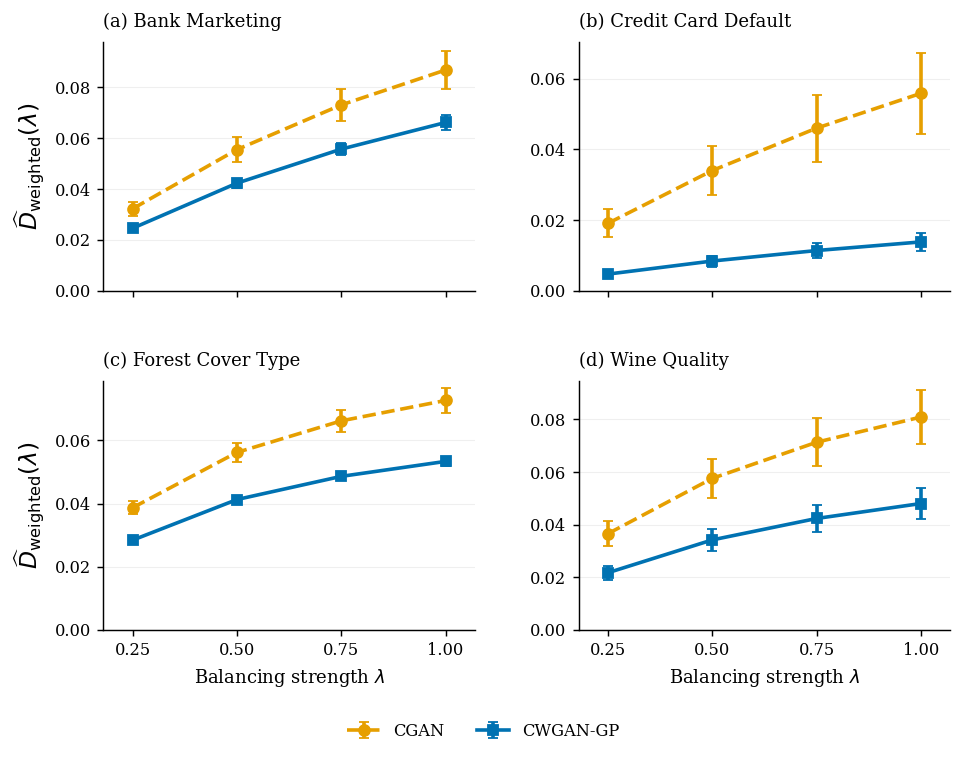

In [5]:
# Run AFTER Manuscript_Results_Analysis_Colab.ipynb's main analysis cell.
# Reads summary CSVs; creates LaTeX Table 2 and four-panel Figure 1.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

OUT = Path('/content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis')
OUT.mkdir(parents=True, exist_ok=True)
stats_path = OUT / 'table_2_paired_wilcoxon_holm.csv'
wf_path = OUT / 'combined_weighted_fidelity_by_seed.csv'
for p in [stats_path, wf_path]:
    if not p.exists():
        raise FileNotFoundError(f'Missing {p}. Run the main manuscript analysis cell first.')

# ---- Table 2: paired Macro-F1 differences, Holm p-values ----
stats = pd.read_csv(stats_path)
order = ['Bank Marketing', 'Credit Card Default', 'Forest Cover Type', 'Wine Quality']
classifiers = ['MLP', 'RF']
opponents = ['CGAN', 'ROS', 'SMOTE']

def format_test(row):
    if pd.isna(row['P_Holm']):
        return r'--'
    delta = float(row['Mean_Delta'])
    p = float(row['P_Holm'])
    s = f'{delta:+.3f} ({p:.3f})'
    if p < 0.05:
        s = r'\textbf{' + s + '}'
    return s

lines = [
    r'\begin{table}[htbp]',
    r'\centering',
    r'\caption{Paired differences in held-out test Macro-F1 between CWGAN-GP and competing augmentation methods. Each cell reports the mean paired difference (Holm-adjusted $p$-value) across ten matched random seeds. Positive differences favor CWGAN-GP; significant comparisons ($p_{\mathrm{Holm}}<0.05$) are bold. Two-sided exact Wilcoxon signed-rank tests were used, with Holm adjustment across the three comparisons within each dataset--classifier combination.}',
    r'\label{tab:paired_comparisons}',
    r'\small',
    r'\begin{adjustbox}{max width=\textwidth}',
    r'\begin{tabular}{llccc}',
    r'\toprule',
    r'Dataset & Classifier & vs. CGAN & vs. ROS & vs. SMOTE \\',
    r'\midrule',
]
for di, ds in enumerate(order):
    for ci, clf in enumerate(classifiers):
        cells = []
        for opp in opponents:
            matches = stats[(stats.Dataset == ds) & (stats.Classifier == clf) &
                            (stats.Comparison == f'CWGAN-GP - {opp}')]
            if len(matches) != 1:
                raise ValueError(f'Expected exactly one row for {ds}/{clf}/{opp}; got {len(matches)}')
            row = matches.iloc[0]
            if int(row['N_pairs']) != 10:
                raise ValueError(f'Incomplete paired seeds for {ds}/{clf}/{opp}')
            cells.append(format_test(row))
        ds_label = ds if ci == 0 else ''
        lines.append(f'{ds_label} & {clf} & ' + ' & '.join(cells) + r' \\')
    if di < len(order) - 1:
        lines.append(r'\midrule')
lines += [r'\bottomrule', r'\end{tabular}', r'\end{adjustbox}', r'\end{table}']
tex_path = OUT / 'table_2_paired_comparisons.tex'
tex_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
print('Saved LaTeX table:', tex_path)

# ---- Figure 1: weighted marginal Wasserstein discrepancy ----
wf = pd.read_csv(wf_path)
required = {'Dataset','Seed','Method','Balancing_Strength','Weighted_Marginal_W1'}
if not required.issubset(wf.columns):
    raise ValueError(f'Fidelity CSV missing columns: {required - set(wf.columns)}')
wf = wf[wf.Method.isin(['CGAN','CWGAN-GP'])].copy()
wf['Balancing_Strength'] = pd.to_numeric(wf['Balancing_Strength'])
wf['Weighted_Marginal_W1'] = pd.to_numeric(wf['Weighted_Marginal_W1'])
summary = (wf.groupby(['Dataset','Method','Balancing_Strength'], as_index=False)
           .agg(N=('Weighted_Marginal_W1','count'),
                Mean=('Weighted_Marginal_W1','mean'),
                SD=('Weighted_Marginal_W1','std')))
expected_lambdas = [0.25, 0.50, 0.75, 1.00]
for ds in order:
    for method in ['CGAN','CWGAN-GP']:
        g = summary[(summary.Dataset == ds) & (summary.Method == method)]
        if len(g) != 4 or not np.allclose(sorted(g.Balancing_Strength), expected_lambdas):
            raise ValueError(f'Missing balancing strengths for {ds}/{method}')
        if not (g.N == 10).all():
            raise ValueError(f'Expected 10 seeds per strength for {ds}/{method}; found {g.N.tolist()}')

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.labelsize': 10, 'axes.titlesize': 10,
    'legend.fontsize': 9, 'pdf.fonttype': 42,
    'ps.fonttype': 42, 'savefig.bbox': 'tight',
})
fig, axes = plt.subplots(2, 2, figsize=(7.4, 5.8), sharex=True)

# Accessible styling dictionary matching user's exact specification
styles = {
    'CGAN': {
        'color': '#E69F00',
        'linestyle': '--',
        'marker': 'o'
    },
    'CWGAN-GP': {
        'color': '#0072B2',
        'linestyle': '-',
        'marker': 's'
    }
}

for ax, ds, letter in zip(axes.flat, order, 'abcd'):
    for method in ['CGAN', 'CWGAN-GP']:
        g = summary[(summary.Dataset == ds) & (summary.Method == method)].sort_values('Balancing_Strength')
        x = g.Balancing_Strength.to_numpy(dtype=float)
        mean = g.Mean.to_numpy(dtype=float)
        sd = g.SD.to_numpy(dtype=float)
        ax.errorbar(x, mean, yerr=sd, label=method, capsize=3,
                    markersize=6, linewidth=2,
                    **styles[method])
    ax.set_title(f'({letter}) {ds}', loc='left', pad=8)
    ax.set_xticks(expected_lambdas)
    ax.set_xticklabels(['0.25', '0.50', '0.75', '1.00'])
    ax.set_xlim(0.18, 1.07)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.20, linewidth=0.6)
    ax.spines[['top','right']].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel(r'Balancing strength $\lambda$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$\widehat{D}_{\mathrm{weighted}}(\lambda)$', fontsize=13)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.015),
           ncol=2, frameon=False)
fig.subplots_adjust(left=0.105, right=0.985, top=0.93, bottom=0.15,
                    wspace=0.28, hspace=0.36)

for ext in ['pdf','png']:
    path = OUT / f'figure_1_weighted_marginal_wasserstein.{ext}'
    fig.savefig(path, dpi=350, facecolor='white')
    print('Saved figure:', path)
plt.show()
summary.to_csv(OUT / 'figure_1_plot_data_mean_sd.csv', index=False)

Dataset              Classifier  Method  
Bank Marketing       MLP         CGAN        10
                                 CWGAN-GP    10
                     RF          CGAN        10
                                 CWGAN-GP    10
Credit Card Default  MLP         CGAN        10
                                 CWGAN-GP    10
                     RF          CGAN        10
                                 CWGAN-GP    10
Forest Cover Type    MLP         CGAN        10
                                 CWGAN-GP    10
                     RF          CGAN        10
                                 CWGAN-GP    10
Wine Quality         MLP         CGAN        10
                                 CWGAN-GP    10
                     RF          CGAN        10
                                 CWGAN-GP    10
dtype: int64


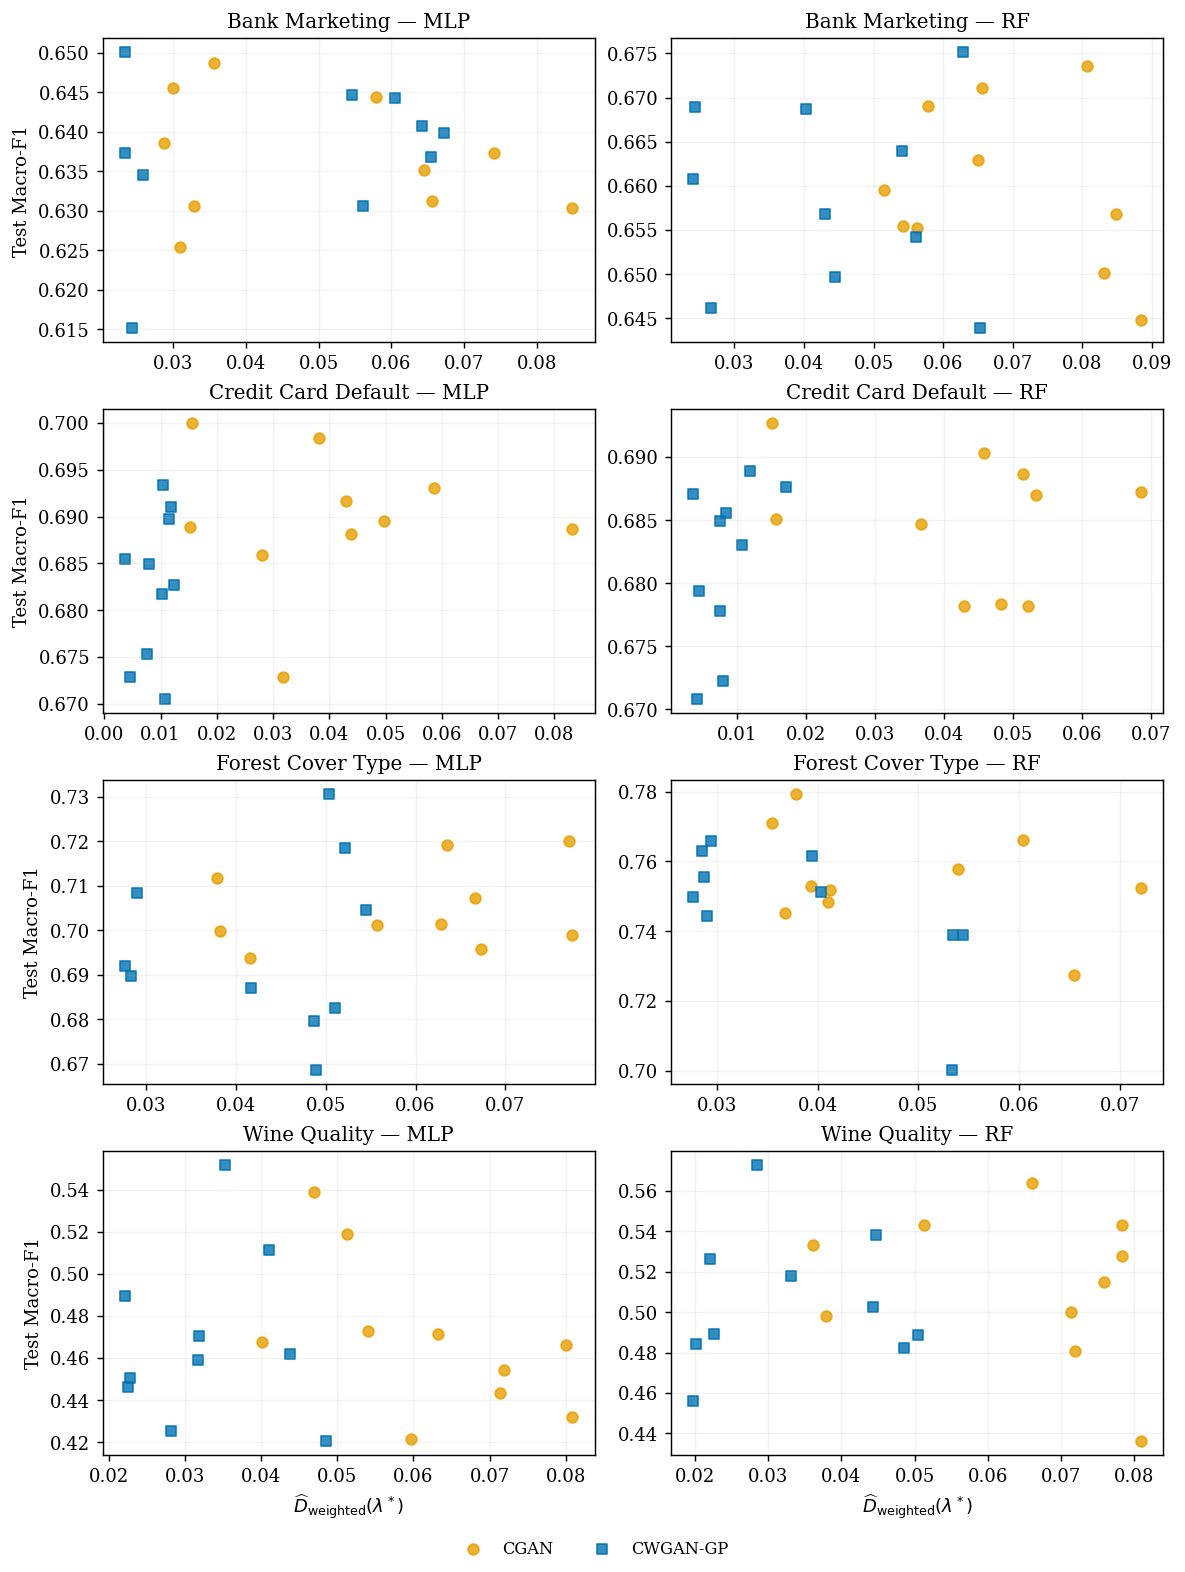

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/CGA Ex/"
    "revision_protocol/manuscript_analysis"
)

df = pd.read_csv(
    folder / "selected_performance_with_fidelity.csv"
)

df = df[df["Method"].isin(["CGAN", "CWGAN-GP"])].copy()

# Check completeness before plotting.
required = [
    "Dataset", "Seed", "Classifier", "Method",
    "Selected_Lambda", "Macro_F1", "Weighted_Marginal_W1"
]
assert all(c in df.columns for c in required)
assert df[required].notna().all().all(), "Missing values detected."
assert not df.duplicated(
    ["Dataset", "Seed", "Classifier", "Method"]
).any(), "Duplicate seed-level results detected."

print(df.groupby(["Dataset", "Classifier", "Method"]).size())

datasets = [
    "Bank Marketing",
    "Credit Card Default",
    "Forest Cover Type",
    "Wine Quality"
]

# Consistent, accessible colors and markers matching Figure 1
colors = {"CGAN": "#E69F00", "CWGAN-GP": "#0072B2"}
markers = {"CGAN": "o", "CWGAN-GP": "s"}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "pdf.fonttype": 42
})

fig, axes = plt.subplots(
    4, 2, figsize=(9, 12), constrained_layout=True
)

for i, dataset in enumerate(datasets):
    for j, clf in enumerate(["MLP", "RF"]):
        ax = axes[i, j]
        subset = df[
            (df["Dataset"] == dataset) &
            (df["Classifier"] == clf)
        ]

        for method in ["CGAN", "CWGAN-GP"]:
            s = subset[subset["Method" ] == method]

            ax.scatter(
                s["Weighted_Marginal_W1"],
                s["Macro_F1"],
                color=colors[method],
                marker=markers[method],
                s=35,
                alpha=0.8,
                label=method
            )

        ax.set_title(f"{dataset} — {clf}", fontsize=11)
        ax.grid(alpha=0.15)

        if j == 0:
            ax.set_ylabel("Test Macro-F1")

        if i == 3:
            ax.set_xlabel(
                r"$\widehat{D}_{\mathrm{weighted}}(\lambda^*)$"
            )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="outside lower center",
    ncol=2,
    frameon=False
)

fig.savefig(
    folder / "figure_2_fidelity_vs_performance.pdf",
    bbox_inches="tight"
)
fig.savefig(
    folder / "figure_2_fidelity_vs_performance.png",
    dpi=350,
    bbox_inches="tight"
)

plt.show()

In [7]:

# ============================================================
# SUPPLEMENTARY TABLES S1 AND S2
# Run after the main manuscript-analysis cells
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Locate analysis outputs
# ------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

OUT = Path(
    "/content/drive/MyDrive/CGA Ex/"
    "revision_protocol/manuscript_analysis"
)

OUT.mkdir(parents=True, exist_ok=True)

print("Files available in analysis folder:")
for p in sorted(OUT.glob("*.csv")):
    print(" -", p.name)

LAMBDAS = [0.25, 0.50, 0.75, 1.00]
METHODS = ["ROS", "SMOTE", "CGAN", "CWGAN-GP"]
DATASETS = [
    "Bank Marketing",
    "Credit Card Default",
    "Forest Cover Type",
    "Wine Quality"
]
CLASSIFIERS = ["MLP", "RF"]

# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def read_results(filename, required_columns):
    path = OUT / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find {filename} in {OUT}.\n"
            "Check the filenames printed above and update "
            "the corresponding variable."
        )

    df = pd.read_csv(path)

    # Normalize column names to handle 'Balancing_Strength' as 'Lambda'
    rename_map = {
        "Balancing_Strength": "Lambda",
        "lambda": "Lambda"
    }
    df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns and new not in df.columns})

    missing = set(required_columns) - set(df.columns)

    if missing:
        raise ValueError(
            f"{filename} is missing columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )

    return df


def normalize_method(x):
    s = str(x).strip().upper().replace("_", "-")
    aliases = {
        "CWGAN": "CWGAN-GP",
        "CWGAN-GP": "CWGAN-GP",
        "CGAN": "CGAN",
        "ROS": "ROS",
        "SMOTE": "SMOTE",
        "REAL": "Real"
    }
    return aliases.get(s, str(x).strip())


def format_mean_sd(mean, sd, digits=3):
    if pd.isna(mean):
        return "--"
    return (
        f"${mean:.{digits}f}"
        f"\\pm{sd:.{digits}f}$"
    )


def latex_escape(s):
    return (
        str(s).replace("&", r"\&")
              .replace("%", r"\%")
              .replace("_", r"\_")
    )


def save_latex_table(df, filename, caption, label,
                     digits=3):
    """
    df must have:
    Dataset, Classifier (optional), Method,
    and four lambda summary columns.
    """

    has_classifier = "Classifier" in df.columns

    if has_classifier:
        colspec = "lllcccc"
        header = (
            r"Dataset & Classifier & Method & "
            r"$\lambda=0.25$ & $\lambda=0.50$ & "
            r"$\lambda=0.75$ & $\lambda=1.00$ \\"
        )
    else:
        colspec = "llcccc"
        header = (
            r"Dataset & Method & "
            r"$\lambda=0.25$ & $\lambda=0.50$ & "
            r"$\lambda=0.75$ & $\lambda=1.00$ \\"
        )

    lines = [
        r"\begin{table}[htbp]",
        r"\centering",
        rf"\caption{{{caption}}}",
        rf"\label{{{label}}}",
        r"\small",
        r"\begin{adjustbox}{max width=\textwidth}",
        rf"\begin{{tabular}}{{{colspec}}}",
        r"\toprule",
        header,
        r"\midrule"
    ]

    previous_dataset = None

    for _, row in df.iterrows():
        dataset = str(row["Dataset"])

        if (
            previous_dataset is not None
            and dataset != previous_dataset
        ):
            lines.append(r"\midrule")

        fields = [latex_escape(dataset)]

        if has_classifier:
            fields.append(
                latex_escape(row["Classifier"])
            )

        fields.append(latex_escape(row["Method"]))

        for lam in LAMBDAS:
            fields.append(
                format_mean_sd(
                    row[f"mean_{lam:.2f}"],
                    row[f"sd_{lam:.2f}"],
                    digits=digits
                )
            )

        lines.append(" & ".join(fields) + r" \\")
        previous_dataset = dataset

    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{adjustbox}",
        r"\end{table}"
    ]

    path = OUT / filename
    path.write_text("\n".join(lines), encoding="utf-8")

    print("Saved:", path)
    return path


# ============================================================
# TABLE S1: PREDICTIVE SENSITIVITY TO AUGMENTATION STRENGTH
# ============================================================

# IMPORTANT:
# Set this to the CSV containing FIXED-LAMBDA test results,
# NOT the selected-lambda performance CSV.
#
# Required columns:
# Dataset, Classifier, Method, Seed, Lambda, Macro_F1
#
# If your file has different column names, rename them
# using the example below.

S1_INPUT = "combined_test_grid_raw.csv"

if (OUT / S1_INPUT).exists():

    perf = read_results(
        S1_INPUT,
        [
            "Dataset", "Classifier", "Method",
            "Seed", "Lambda", "Macro_F1"
        ]
    )

    perf["Method"] = perf["Method"].map(
        normalize_method
    )
    perf["Lambda"] = pd.to_numeric(
        perf["Lambda"], errors="raise"
    )

    perf = perf[
        perf["Method"].isin(METHODS)
        & perf["Lambda"].isin(LAMBDAS)
    ].copy()

    # Verify one observation per experimental combination.
    keys = [
        "Dataset", "Classifier",
        "Method", "Seed", "Lambda"
    ]

    if perf.duplicated(keys).any():
        raise ValueError(
            "Duplicate fixed-lambda performance records found."
        )

    summary1 = (
        perf.groupby(
            [
                "Dataset",
                "Classifier",
                "Method",
                "Lambda",
            ]
        )["Macro_F1"]
        .agg(mean="mean", sd="std", n="count")
        .reset_index()
    )

    # Require all ten seeds for every reported combination.
    if (summary1["n"] != 10).any():
        raise ValueError(
            "Some S1 combinations do not contain ten seeds:\n"
            + summary1.loc[
                summary1["n"] != 10
            ].to_string(index=False)
        )

    # Require a complete grid.
    expected = pd.MultiIndex.from_product(
        [DATASETS, CLASSIFIERS, METHODS, LAMBDAS],
        names=["Dataset", "Classifier", "Method", "Lambda"]
    )

    actual = pd.MultiIndex.from_frame(
        summary1[
            ["Dataset", "Classifier", "Method", "Lambda"]
        ]
    )

    missing = expected.difference(actual)

    if len(missing):
        raise ValueError(
            f"S1 is missing {len(missing)} combinations:\n"
            + str(missing.tolist()[:12])
        )

    summary1.to_csv(
        OUT / "table_S1_long.csv", index=False
    )

    wide1 = summary1.pivot(
        index=["Dataset", "Classifier", "Method"],
        columns="Lambda",
        values=["mean", "sd"]
    )

    wide1.columns = [
        f"{stat}_{lam:.2f}"
        for stat, lam in wide1.columns
    ]

    wide1 = wide1.reset_index()

    wide1["Dataset"] = pd.Categorical(
        wide1["Dataset"], DATASETS, ordered=True
    )
    wide1["Classifier"] = pd.Categorical(
        wide1["Classifier"], CLASSIFIERS, ordered=True
    )
    wide1["Method"] = pd.Categorical(
        wide1["Method"], METHODS, ordered=True
    )

    wide1 = wide1.sort_values(
        ["Dataset", "Classifier", "Method"]
    )

    wide1.to_csv(
        OUT / "table_S1_summary.csv", index=False
    )

    save_latex_table(
        wide1,
        "table_S1_augmentation_sensitivity.tex",
        caption=(
            "Sensitivity of held-out test Macro-F1 to "
            "augmentation strength. Values represent "
            "mean $\\pm$ standard deviation across ten "
            "random seeds at each fixed value of "
            "$\\lambda$. These results are distinct "
            "from the validation-selected results "
            "reported in the main classification table."
        ),
        label="tab:supp_augmentation_sensitivity",
        digits=3
    )

    print("\nTABLE S1")
    display(wide1)

else:
    print(
        "\nS1 NOT GENERATED.\n"
        f"File not found: {S1_INPUT}\n"
        "The fixed-lambda test results must be exported "
        "from the original experiment. Selected-lambda "
        "results cannot reconstruct this table."
    )


# ============================================================
# TABLE S2: WEIGHTED MARGINAL WASSERSTEIN SENSITIVITY
# ============================================================

# This should be the seed-level weighted-fidelity file
# generated by your manuscript-analysis notebook.

S2_INPUT = "combined_weighted_fidelity_by_seed.csv"

fid = pd.read_csv(OUT / S2_INPUT)

print("\nS2 source columns:", fid.columns.tolist())

# Normalize column names if needed.
rename_candidates = {
    "lambda": "Lambda",
    "Balancing_Strength": "Lambda",
    "method": "Method",
    "Generator": "Method",
    "dataset": "Dataset",
    "seed": "Seed",
    "Weighted_W1": "Weighted_Marginal_W1",
    "Weighted_Discrepancy": "Weighted_Marginal_W1",
    "D_weighted": "Weighted_Marginal_W1"
}

fid = fid.rename(
    columns={
        old: new
        for old, new in rename_candidates.items()
        if old in fid.columns and new not in fid.columns
    }
)

required = [
    "Dataset", "Method", "Seed",
    "Lambda", "Weighted_Marginal_W1"
]

missing = set(required) - set(fid.columns)

if missing:
    raise ValueError(
        f"S2 source missing columns: {missing}\n"
        f"Available: {list(fid.columns)}"
    )

fid["Method"] = fid["Method"].map(normalize_method)
fid["Lambda"] = pd.to_numeric(
    fid["Lambda"], errors="raise"
)

fid = fid[
    fid["Method"].isin(["CGAN", "CWGAN-GP"])
    & fid["Lambda"].isin(LAMBDAS)
].copy()

keys = ["Dataset", "Method", "Seed", "Lambda"]

if fid.duplicated(keys).any():
    raise ValueError(
        "Duplicate weighted-fidelity records found."
    )

summary2 = (
    fid.groupby(
        ["Dataset", "Method", "Lambda"]
    )["Weighted_Marginal_W1"]
    .agg(mean="mean", sd="std", n="count")
    .reset_index()
)

if (summary2["n"] != 10).any():
    raise ValueError(
        "Some S2 combinations do not contain ten seeds:\n"
        + summary2.loc[
            summary2["n"] != 10
        ].to_string(index=False)
    )

expected2 = pd.MultiIndex.from_product(
    [
        DATASETS,
        ["CGAN", "CWGAN-GP"],
        LAMBDAS
    ],
    names=["Dataset", "Method", "Lambda"]
)

actual2 = pd.MultiIndex.from_frame(
    summary2[["Dataset", "Method", "Lambda"]]
)

missing2 = expected2.difference(actual2)

if len(missing2):
    raise ValueError(
        f"S2 is missing combinations: {missing2.tolist()}"
    )

summary2.to_csv(
    OUT / "table_S2_long.csv", index=False
)

wide2 = summary2.pivot(
    index=["Dataset", "Method"],
    columns="Lambda",
    values=["mean", "sd"]
)

wide2.columns = [
    f"{stat}_{lam:.2f}"
    for stat, lam in wide2.columns
]

wide2 = wide2.reset_index()

wide2["Dataset"] = pd.Categorical(
    wide2["Dataset"], DATASETS, ordered=True
)
wide2["Method"] = pd.Categorical(
    wide2["Method"],
    ["CGAN", "CWGAN-GP"],
    ordered=True
)

wide2 = wide2.sort_values(
    ["Dataset", "Method"]
)

wide2.to_csv(
    OUT / "table_S2_summary.csv", index=False
)

save_latex_table(
    wide2,
    "table_S2_wasserstein_sensitivity.tex",
    caption=(
        "Weighted marginal Wasserstein discrepancy "
        "across augmentation strengths for CGAN and "
        "CWGAN-GP. Values represent mean $\\pm$ standard "
        "deviation across ten random seeds. The "
        "discrepancy combines class-specific average "
        "feature-wise Wasserstein--1 distances using "
        "post-augmentation class proportions and "
        "synthetic fractions."
    ),
    label="tab:supp_wasserstein_sensitivity",
    digits=4
)

print("\nTABLE S2")
display(wide2)

print("\nSupplementary table generation complete.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files available in analysis folder:
 - combined_class_recall_raw.csv
 - combined_fidelity_raw.csv
 - combined_selected_test_raw.csv
 - combined_test_grid_raw.csv
 - combined_weighted_fidelity_by_seed.csv
 - data_completeness_audit.csv
 - exploratory_fidelity_performance_correlations.csv
 - figure_1_plot_data_mean_sd.csv
 - paired_seed_differences.csv
 - selected_performance_with_fidelity.csv
 - table_1_performance_mean_sd.csv
 - table_1_performance_print_ready.csv
 - table_2_paired_wilcoxon_holm.csv
 - table_3_selected_lambda_counts.csv
 - table_4_classwise_marginal_fidelity.csv
 - table_5_weighted_fidelity_by_lambda.csv
 - table_6_selected_classwise_recall.csv
 - table_S1_long.csv
 - table_S1_summary.csv
 - table_S2_long.csv
 - table_S2_summary.csv
 - table_S3_minority_recall.csv
 - table_S3_minority_recall_long.csv
Saved: /content/drive/MyDrive/CGA Ex/revis

,Dataset,Classifier,Method,mean_0.25,mean_0.50,mean_0.75,mean_1.00,sd_0.25,sd_0.50,sd_0.75,sd_1.00
2,Bank Marketing,MLP,ROS,0.621391,0.615328,0.603304,0.600795,0.008116,0.007925,0.013164,0.011080
3,Bank Marketing,MLP,SMOTE,0.622227,0.610862,0.603919,0.602441,0.011793,0.012631,0.009530,0.008573
0,Bank Marketing,MLP,CGAN,0.636560,0.631995,0.633946,0.631195,0.009515,0.010284,0.006185,0.009337
1,Bank Marketing,MLP,CWGAN-GP,0.635431,0.635884,0.638524,0.633417,0.009380,0.008605,0.006065,0.007347
6,Bank Marketing,RF,ROS,0.678783,0.679747,0.678737,0.678019,0.009960,0.008455,0.008608,0.008782
7,Bank Marketing,RF,SMOTE,0.675507,0.680908,0.682032,0.684027,0.009030,0.009871,0.008162,0.009292
4,Bank Marketing,RF,CGAN,0.660262,0.661420,0.660594,0.660050,0.007346,0.010041,0.008941,0.010366
5,Bank Marketing,RF,CWGAN-GP,0.660353,0.659109,0.660269,0.659376,0.009000,0.010185,0.009549,0.009854
10,Credit Card Default,MLP,ROS,0.689150,0.677500,0.672364,0.653183,0.007920,0.010678,0.007545,0.008642
11,Credit Card Default,MLP,SMOTE,0.687164,0.673666,0.661167,0.649531,0.008128,0.006845,0.019773,0.014354



S2 source columns: ['Dataset', 'Seed', 'Method', 'Balancing_Strength', 'Weighted_Marginal_W1']
Saved: /content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis/table_S2_wasserstein_sensitivity.tex

TABLE S2


,Dataset,Method,mean_0.25,mean_0.50,mean_0.75,mean_1.00,sd_0.25,sd_0.50,sd_0.75,sd_1.00
0,Bank Marketing,CGAN,0.032226,0.055454,0.072992,0.086702,0.002833,0.004874,0.006416,0.007621
1,Bank Marketing,CWGAN-GP,0.024566,0.042273,0.055642,0.066093,0.001053,0.001813,0.002386,0.002834
2,Credit Card Default,CGAN,0.019083,0.034005,0.045994,0.055838,0.003921,0.006987,0.009451,0.011474
3,Credit Card Default,CWGAN-GP,0.004724,0.008418,0.011386,0.013823,0.000874,0.001558,0.002108,0.002559
4,Forest Cover Type,CGAN,0.038689,0.056223,0.066227,0.072695,0.002066,0.003002,0.003537,0.003882
5,Forest Cover Type,CWGAN-GP,0.028406,0.041278,0.048623,0.053372,0.000694,0.001009,0.001188,0.001304
6,Wine Quality,CGAN,0.036529,0.057570,0.071313,0.080901,0.004650,0.007328,0.009078,0.010299
7,Wine Quality,CWGAN-GP,0.021677,0.034162,0.042317,0.048007,0.002694,0.004246,0.005260,0.005967



Supplementary table generation complete.


In [8]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# --------------------------------------------------
# 1. Load validation-selected classification results
# --------------------------------------------------

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

BASE = Path(
    "/content/drive/MyDrive/CGA Ex/revision_protocol/manuscript_analysis"
)

INPUT = BASE / "combined_selected_test_raw.csv"
CLASS_RECALL_INPUT = BASE / "combined_class_recall_raw.csv"

df = pd.read_csv(INPUT)
print("Loaded main results. Length:", len(df))


# --------------------------------------------------
# 2. Reconstruct minority recall from class-wise recall
# --------------------------------------------------

import numpy as np

cr = pd.read_csv(CLASS_RECALL_INPUT)

# Verify these class IDs against training-label frequencies.
# Updated: Wine Quality minority class is mapped to Class_ID 0 (Low 3-4) instead of 1 (Medium 5-6).
minority_class_mapping = {
    "Bank Marketing": 1,
    "Credit Card Default": 1,
    "Forest Cover Type": 3,
    "Wine Quality": 0
}

methods = ["Real", "ROS", "SMOTE", "CGAN", "CWGAN-GP"]

df = df[df["Method"].isin(methods)].copy()

required = {
    "Dataset", "Classifier", "Method", "Seed",
    "Selected_Lambda", "Minority_Recall"
}
assert required.issubset(df.columns)

# Normalize matching keys
df["Match_Lambda" ] = (
    pd.to_numeric(df["Selected_Lambda"], errors="coerce")
    .fillna(0.0)
    .round(6)
)

cr["Match_Lambda"] = (
    pd.to_numeric(cr["Balancing_Strength"], errors="coerce")
    .fillna(0.0)
    .round(6)
)

df["Seed"] = pd.to_numeric(df["Seed"])
cr["Seed"] = pd.to_numeric(cr["Seed"])
cr["Class_ID"] = pd.to_numeric(cr["Class_ID"])

# Select the designated minority class for each dataset
cr["Target_Minority_Class"] = cr["Dataset"].map(
    minority_class_mapping
)

minority_cr = cr.loc[
    cr["Class_ID"] == cr["Target_Minority_Class"],
    [
        "Dataset", "Classifier", "Method",
        "Seed", "Match_Lambda", "Recall"
    ]
].copy()

keys = [
    "Dataset", "Classifier", "Method",
    "Seed", "Match_Lambda"
]

# Prevent accidental many-to-many matching
if minority_cr.duplicated(keys).any():
    raise ValueError(
        "Duplicate class-recall records for matching keys."
    )

# Preserve original records and safely attach recall
merged = df.merge(
    minority_cr.rename(
        columns={"Recall": "Reconstructed_Recall"}
    ),
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

if len(merged) != len(df):
    raise ValueError("Merge changed the number of rows.")

# Compare existing and reconstructed values
both = (
    merged["Minority_Recall"].notna()
    & merged["Reconstructed_Recall"].notna()
)

if both.any():
    original = pd.to_numeric(
        merged.loc[both, "Minority_Recall"]
    )
    reconstructed = pd.to_numeric(
        merged.loc[both, "Reconstructed_Recall"]
    )

    if not np.allclose(
        original, reconstructed, atol=1e-8, rtol=0
    ):
        raise ValueError(
            "Existing minority recall disagrees "
            "with reconstructed class recall."
        )

merged["Minority_Recall"] = (
    pd.to_numeric(
        merged["Minority_Recall"], errors="coerce"
    ).fillna(
        pd.to_numeric(
            merged["Reconstructed_Recall"],
            errors="coerce"
        )
    )
)

print("Merge status:")
print(merged["_merge"].value_counts())

print("\nMissing minority recall by dataset:")
print(
    merged.groupby("Dataset")["Minority_Recall"]
    .apply(lambda x: x.isna().sum())
)

# Do not silently drop incomplete results
if merged["Minority_Recall"].isna().any():
    raise ValueError(
        "Some minority recall values remain missing. "
        "Inspect the matching keys and class IDs."
    )

if not merged["Minority_Recall"].between(0, 1).all():
    raise ValueError("Recall values must be between 0 and 1.")

df = merged.drop(
    columns=[
        "Match_Lambda", "Reconstructed_Recall", "_merge"
    ]
)

# Validate all expected seed-level combinations
seed_keys = ["Dataset", "Classifier", "Method", "Seed"]

if df.duplicated(seed_keys).any():
    raise ValueError("Duplicate seed-level records.")

counts = df.groupby(
    ["Dataset", "Classifier", "Method"]
)["Seed"].nunique()

if len(df) != 400 or len(counts) != 40 or not counts.eq(10).all():
    raise ValueError(
        "Expected 400 records: "
        "4 datasets x 2 classifiers x 5 methods x 10 seeds."
    )

print("\nValidation passed. Ready to construct Table S3.")


# --------------------------------------------------
# 5. Compute mean and sample standard deviation
# --------------------------------------------------

summary = (
    df.groupby(
        ["Dataset", "Classifier", "Method"]
    )["Minority_Recall"]
    .agg(Mean="mean", SD="std", N="count")
    .reset_index()
)

print("\nNumber of seeds per combination:")
print(summary["N"].value_counts())

if len(summary) != 40 or not (summary["N"] == 10).all():
    print("Warning: Expected 40 dataset-classifier-method combinations with exactly 10 seeds each, but got:")
    display(summary[summary["N"] != 10])

# --------------------------------------------------
# 6. Create manuscript-ready table
# --------------------------------------------------

summary["Result"] = summary.apply(
    lambda r: (
        f"${r['Mean']:.3f}\\pm{r['SD']:.3f}$" if pd.notna(r['SD']) else f"${r['Mean']:.3f}\\pm 0.000$"
    ),
    axis=1
)

table_s3 = summary.pivot(
    index=["Dataset", "Classifier"],
    columns="Method",
    values="Result"
)

table_s3 = table_s3.reindex(columns=methods)
table_s3 = table_s3.reset_index()

display(table_s3)

# --------------------------------------------------
# 7. Save numerical and formatted CSV files
# --------------------------------------------------

summary.to_csv(
    BASE / "table_S3_minority_recall_long.csv",
    index=False
)

table_s3.to_csv(
    BASE / "table_S3_minority_recall.csv",
    index=False
)

# --------------------------------------------------
# 8. Export LaTeX table
# --------------------------------------------------

table_s3 = table_s3.fillna("--")

latex = table_s3.to_latex(
    index=False,
    escape=False,
    column_format="llccccc",
    caption=(
        "Minority-class recall across four benchmark "
        "datasets. Values represent mean $\\pm$ standard "
        "deviation over ten random seeds. For augmented "
        "methods, the balancing strength is selected "
        "using validation Macro-F1."
    ),
    label="tab:supp_minority_recall"
)

latex = latex.replace(
    "\\begin{tabular}",
    "\\small\n\\begin{adjustbox}{max width=\\textwidth}\n"
    "\\begin{tabular}"
)

latex = latex.replace(
    "\\end{tabular}",
    "\\end{tabular}\n\\end{adjustbox}"
)

latex = latex.replace(
    "\\begin{table}",
    "\\begin{table}[htbp]"
)

(BASE / "table_S3_minority_recall.tex").write_text(
    latex,
    encoding="utf-8"
)

print("Supplementary Table S3 generated successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded main results. Length: 400
Merge status:
_merge
both          300
left_only     100
right_only      0
Name: count, dtype: int64

Missing minority recall by dataset:
Dataset
Bank Marketing         0
Credit Card Default    0
Forest Cover Type      0
Wine Quality           0
Name: Minority_Recall, dtype: int64

Validation passed. Ready to construct Table S3.

Number of seeds per combination:
N
10    40
Name: count, dtype: int64


Method,Dataset,Classifier,Real,ROS,SMOTE,CGAN,CWGAN-GP
0,Bank Marketing,MLP,$0.321\pm0.015$,$0.352\pm0.025$,$0.345\pm0.025$,$0.307\pm0.024$,$0.312\pm0.022$
1,Bank Marketing,RF,$0.292\pm0.013$,$0.377\pm0.017$,$0.400\pm0.013$,$0.290\pm0.015$,$0.287\pm0.018$
2,Credit Card Default,MLP,$0.380\pm0.031$,$0.452\pm0.023$,$0.459\pm0.030$,$0.410\pm0.021$,$0.399\pm0.021$
3,Credit Card Default,RF,$0.375\pm0.010$,$0.422\pm0.014$,$0.444\pm0.018$,$0.380\pm0.010$,$0.377\pm0.010$
4,Forest Cover Type,MLP,$0.596\pm0.097$,$0.694\pm0.082$,$0.672\pm0.058$,$0.604\pm0.094$,$0.560\pm0.073$
5,Forest Cover Type,RF,$0.609\pm0.060$,$0.672\pm0.060$,$0.787\pm0.049$,$0.579\pm0.066$,$0.564\pm0.085$
6,Wine Quality,MLP,$0.062\pm0.071$,$0.223\pm0.092$,$0.238\pm0.164$,$0.038\pm0.054$,$0.062\pm0.101$
7,Wine Quality,RF,$0.015\pm0.032$,$0.031\pm0.054$,$0.169\pm0.140$,$0.023\pm0.037$,$0.038\pm0.054$


Supplementary Table S3 generated successfully.


In [9]:

# ============================================================
# TABLE 2: PAIRED WILCOXON TESTS WITH EXACT SIGN ENUMERATION
# AND HOLM MULTIPLE-COMPARISON CORRECTION
# ============================================================

from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests

# 1. File paths
OUT = Path(
    "/content/drive/MyDrive/CGA Ex/"
    "revision_protocol/manuscript_analysis"
)

input_file = OUT / "combined_selected_test_raw.csv"

if not input_file.exists():
    raise FileNotFoundError(
        f"Missing {input_file}. Run the main analysis cell first."
    )

df = pd.read_csv(input_file)

# 2. Exact sign-enumerated Wilcoxon p-value
def exact_signed_rank_pvalue(diff):
    d = np.asarray(diff, dtype=float)

    if not np.isfinite(d).all():
        raise ValueError("Non-finite paired differences found.")

    # Standard Wilcoxon zero_method='wilcox'
    d = d[d != 0]

    if len(d) == 0:
        return 1.0

    ranks = rankdata(np.abs(d), method="average")

    observed = np.sum(ranks[d > 0])
    total = np.sum(ranks)

    # Enumerate all 2^n possible sign assignments
    signs = np.array(
        list(product([-1, 1], repeat=len(d)))
    )

    w_plus = (signs > 0) @ ranks

    observed_stat = min(observed, total - observed)
    perm_stats = np.minimum(w_plus, total - w_plus)

    return float(
        np.mean(perm_stats <= observed_stat + 1e-12)
    )


# 3. Dataset and classifier order
datasets = [
    "Bank Marketing",
    "Credit Card Default",
    "Forest Cover Type",
    "Wine Quality"
]

classifiers = ["MLP", "RF"]
competitors = ["CGAN", "ROS", "SMOTE"]

expected_seeds = set(range(44, 54))

# 4. Calculate paired tests
results = []

for dataset in datasets:
    for clf in classifiers:

        sub = df[
            (df["Dataset"] == dataset) &
            (df["Classifier"] == clf)
        ].copy()

        if sub.empty:
            raise ValueError(f"No data for {dataset}/{clf}")

        if sub.duplicated(["Seed", "Method"]).any():
            raise ValueError(
                f"Duplicate Seed/Method rows: {dataset}/{clf}"
            )

        pivot = sub.pivot(
            index="Seed",
            columns="Method",
            values="Macro_F1"
        )

        methods_needed = ["CWGAN-GP"] + competitors

        if not set(methods_needed).issubset(pivot.columns):
            raise ValueError(
                f"Missing methods for {dataset}/{clf}"
            )

        if set(pivot.index) != expected_seeds:
            raise ValueError(
                f"Incorrect seeds for {dataset}/{clf}"
            )

        if pivot[methods_needed].isna().any().any():
            raise ValueError(
                f"Missing Macro-F1 values for {dataset}/{clf}"
            )

        raw_p = []
        group = []

        for opponent in competitors:

            diff = (
                pivot["CWGAN-GP"] -
                pivot[opponent]
            ).to_numpy(dtype=float)

            p = exact_signed_rank_pvalue(diff)

            raw_p.append(p)

            group.append({
                "Dataset": dataset,
                "Classifier": clf,
                "Comparison": "CWGAN-GP - " + opponent,
                "N_pairs": len(diff),
                "Mean_Delta": np.mean(diff),
                "SD_Delta": np.std(diff, ddof=1),
                "Median_Delta": np.median(diff),
                "Positive_Seeds": int(np.sum(diff > 0)),
                "Negative_Seeds": int(np.sum(diff < 0)),
                "Zero_Seeds": int(np.sum(diff == 0)),
                "P_unadjusted": p
            })

        # Holm adjustment within each dataset/classifier
        adjusted = multipletests(
            raw_p,
            alpha=0.05,
            method="holm"
        )[1]

        for row, p_adj in zip(group, adjusted):
            row["P_Holm"] = float(p_adj)
            row["Significant_05"] = bool(p_adj < 0.05)
            results.append(row)


# 5. Save complete statistical results
stats = pd.DataFrame(results)

stats.to_csv(
    OUT / "table_2_paired_wilcoxon_holm_exact.csv",
    index=False
)

# 6. Format publication table
def format_cell(row):
    delta = row["Mean_Delta"]
    p = row["P_Holm"]

    value = f"{delta:+.3f} ({p:.3f})"

    if p < 0.05:
        value = r"\textbf{" + value + "}"

    return value


table_rows = []

for dataset in datasets:
    for clf in classifiers:

        subset = stats[
            (stats["Dataset"] == dataset) &
            (stats["Classifier"] == clf)
        ]

        row = {
            "Dataset": dataset,
            "Classifier": clf
        }

        for opponent in competitors:
            result = subset[
                subset["Comparison"] ==
                "CWGAN-GP - " + opponent
            ].iloc[0]

            row["vs. " + opponent] = format_cell(result)

        table_rows.append(row)

publication_table = pd.DataFrame(table_rows)

# 7. Display table
print("\nTABLE 2: Paired Wilcoxon comparisons")
print("Mean difference (Holm-adjusted p-value)\n")

print(publication_table.to_string(index=False))

# 8. Save formatted table
publication_table.to_csv(
    OUT / "table_2_paired_publication_exact.csv",
    index=False
)

# 9. Generate LaTeX table
latex_lines = [
    r"\begin{table}[htbp]",
    r"\centering",
    r"\caption{Paired differences in held-out test "
    r"Macro-F1 between CWGAN-GP and competing "
    r"augmentation methods. Each cell reports the "
    r"mean paired difference (Holm-adjusted "
    r"$p$-value) across ten matched random seeds. "
    r"Positive differences favor CWGAN-GP; "
    r"significant comparisons ($p_{\mathrm{Holm}}<0.05$) "
    r"are shown in bold.}",
    r"\label{tab:paired_comparisons}",
    r"\small",
    r"\begin{tabular}{llccc}",
    r"\toprule",
    r"Dataset & Classifier & vs. CGAN & vs. ROS & vs. SMOTE \\",
    r"\midrule"
]

for i, dataset in enumerate(datasets):

    for clf in classifiers:

        row = publication_table[
            (publication_table["Dataset"] == dataset) &
            (publication_table["Classifier"] == clf)
        ].iloc[0]

        name = dataset if clf == "MLP" else ""

        line = (
            f"{name} & {clf} & "
            f"{row['vs. CGAN']} & "
            f"{row['vs. ROS']} & "
            f"{row['vs. SMOTE']} "
            + r"\\"
        )

        latex_lines.append(line)

    if i < len(datasets) - 1:
        latex_lines.append(r"\midrule")

latex_lines.extend([
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}"
])

latex_code = "\n".join(latex_lines)

latex_path = OUT / "table_2_paired_comparisons_exact.tex"

latex_path.write_text(latex_code, encoding="utf-8")

print("\nLaTeX table saved to:", latex_path)
print("\n", latex_code)

# 10. Statistical summary
print("\nSTATISTICAL SUMMARY")

print(
    "Total comparisons:",
    len(stats)
)

print(
    "Significant comparisons:",
    int(stats["Significant_05"].sum())
)

print(
    "Significant favoring CWGAN-GP:",
    int(
        (
            stats["Significant_05"] &
            (stats["Mean_Delta"] > 0)
        ).sum()
    )
)

print(
    "Significant favoring competitors:",
    int(
        (
            stats["Significant_05"] &
            (stats["Mean_Delta"] < 0)
        ).sum()
    )
)

# 11. Compare with the original statistical output
old_path = OUT / "table_2_paired_wilcoxon_holm.csv"

if old_path.exists():
    old = pd.read_csv(old_path)

    comparison = stats.merge(
        old[
            ["Dataset", "Classifier",
             "Comparison", "P_Holm"]
        ],
        on=["Dataset", "Classifier", "Comparison"],
        how="left",
        suffixes=("_new", "_old"),
        validate="one_to_one"
    )

    comparison["Changed"] = (
        ~np.isclose(
            comparison["P_Holm_new"],
            comparison["P_Holm_old"],
            atol=1e-10,
            rtol=0,
            equal_nan=True
        )
    )

    print("\nP-VALUE COMPARISON WITH ORIGINAL TABLE")
    print(
        comparison[
            ["Dataset", "Classifier", "Comparison",
             "P_Holm_old", "P_Holm_new", "Changed"]
        ].to_string(index=False)
    )



TABLE 2: Paired Wilcoxon comparisons
Mean difference (Holm-adjusted p-value)

            Dataset Classifier                vs. CGAN                 vs. ROS               vs. SMOTE
     Bank Marketing        MLP          +0.001 (1.000) \textbf{+0.015 (0.029)} \textbf{+0.014 (0.029)}
     Bank Marketing         RF          -0.001 (0.193) \textbf{-0.020 (0.006)} \textbf{-0.023 (0.006)}
Credit Card Default        MLP          -0.007 (0.262)          -0.006 (0.146)          -0.005 (0.262)
Credit Card Default         RF          -0.003 (0.160) \textbf{-0.011 (0.006)} \textbf{-0.013 (0.006)}
  Forest Cover Type        MLP          -0.009 (0.131) \textbf{-0.047 (0.006)} \textbf{-0.035 (0.006)}
  Forest Cover Type         RF \textbf{-0.008 (0.037)} \textbf{-0.048 (0.006)} \textbf{-0.053 (0.006)}
       Wine Quality        MLP          -0.000 (1.000) \textbf{-0.044 (0.012)} \textbf{-0.050 (0.012)}
       Wine Quality         RF          -0.008 (0.645)          -0.011 (0.645) \textbf{-0.062 (0.